# New Inference

In [1]:
import os
# 1. 坚持使用国内镜像站
os.environ["HF_ENDPOINT"] = "https://hf-mirror.com"

# 2. 强行清空系统的代理设置（拔掉幽灵网线）
os.environ["HTTP_PROXY"] = ""
os.environ["HTTPS_PROXY"] = ""
os.environ["http_proxy"] = ""
os.environ["https_proxy"] = ""
import torch
from PIL import Image
import argparse

import os, json, random
import pandas as pd
import matplotlib.pyplot as plt
import glob, re

from tqdm.notebook import tqdm
import numpy as np

from safetensors.torch import load_file
import matplotlib.image as mpimg
import copy
import gc
from transformers import CLIPTextModel, CLIPTokenizer

import diffusers
from diffusers import DiffusionPipeline
from diffusers import AutoencoderKL, DDPMScheduler, DiffusionPipeline, UNet2DConditionModel, LMSDiscreteScheduler
from diffusers.loaders import AttnProcsLayers
from diffusers.models.attention_processor import LoRAAttnProcessor, AttentionProcessor
from typing import Any, Dict, List, Optional, Tuple, Union
from trainscripts.textsliders.lora import LoRANetwork, DEFAULT_TARGET_REPLACE, UNET_TARGET_REPLACE_MODULE_CONV

In [2]:
def flush():
    torch.cuda.empty_cache()
    gc.collect()
flush()
width = 512
height = 512
steps = 50
cfg_scale = 7.5
pretrained_sd_model = "CompVis/stable-diffusion-v1-4"

In [3]:
pretrained_model_name_or_path = "CompVis/stable-diffusion-v1-4"

revision = None
device = 'cuda:0'
rank = 4
weight_dtype = torch.float16

# Load scheduler, tokenizer and models.
noise_scheduler = LMSDiscreteScheduler(beta_start=0.00085, beta_end=0.012, beta_schedule="scaled_linear", num_train_timesteps=1000)
tokenizer = CLIPTokenizer.from_pretrained(
    pretrained_model_name_or_path, subfolder="tokenizer", revision=revision
)
text_encoder = CLIPTextModel.from_pretrained(
    pretrained_model_name_or_path, subfolder="text_encoder", revision=revision
)
vae = AutoencoderKL.from_pretrained(pretrained_model_name_or_path, subfolder="vae", revision=revision)
unet = UNet2DConditionModel.from_pretrained(
    pretrained_model_name_or_path, subfolder="unet", revision=revision
)
# freeze parameters of models to save more memory
unet.requires_grad_(False)
unet.to(device, dtype=weight_dtype)
vae.requires_grad_(False)

text_encoder.requires_grad_(False)

# For mixed precision training we cast all non-trainable weigths (vae, non-lora text_encoder and non-lora unet) to half-precision
# as these weights are only used for inference, keeping weights in full precision is not required.


# Move unet, vae and text_encoder to device and cast to weight_dtype
vae.requires_grad_(False)
vae.to(device, dtype=weight_dtype)
text_encoder.to(device, dtype=weight_dtype)

CLIPTextModel(
  (text_model): CLIPTextTransformer(
    (embeddings): CLIPTextEmbeddings(
      (token_embedding): Embedding(49408, 768)
      (position_embedding): Embedding(77, 768)
    )
    (encoder): CLIPEncoder(
      (layers): ModuleList(
        (0-11): 12 x CLIPEncoderLayer(
          (self_attn): CLIPAttention(
            (k_proj): Linear(in_features=768, out_features=768, bias=True)
            (v_proj): Linear(in_features=768, out_features=768, bias=True)
            (q_proj): Linear(in_features=768, out_features=768, bias=True)
            (out_proj): Linear(in_features=768, out_features=768, bias=True)
          )
          (layer_norm1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
          (mlp): CLIPMLP(
            (activation_fn): QuickGELUActivation()
            (fc1): Linear(in_features=768, out_features=3072, bias=True)
            (fc2): Linear(in_features=3072, out_features=768, bias=True)
          )
          (layer_norm2): LayerNorm((768,), eps=1e

In [7]:
# path to your model file
lora_weights = [

    "D:/pycharm/sliders/models/fatcatslider_alpha1.0_rank4_noxattn/fatcatslider_alpha1.0_rank4_noxattn_500steps.safetensors",

]


create LoRA for U-Net: 150 modules.
正在测试 Prompt: a highly detailed photorealistic full body shot of a cat standing on a wooden floor, 8k resolution | 种子: 888
正在生成 Scale = -5.0 的图像...


C:\Users\30549\AppData\Local\Temp\ipykernel_16304\261080807.py:75: FutureWarning: Accessing config attribute `in_channels` directly via 'UNet2DConditionModel' object attribute is deprecated. Please access 'in_channels' over 'UNet2DConditionModel's config object instead, e.g. 'unet.config.in_channels'.
  latents = torch.randn((batch_size, unet.in_channels, height // 8, width // 8), generator=generator)


正在生成 Scale = 0.0 的图像...
正在生成 Scale = 2.0 的图像...
正在生成 Scale = 4.0 的图像...


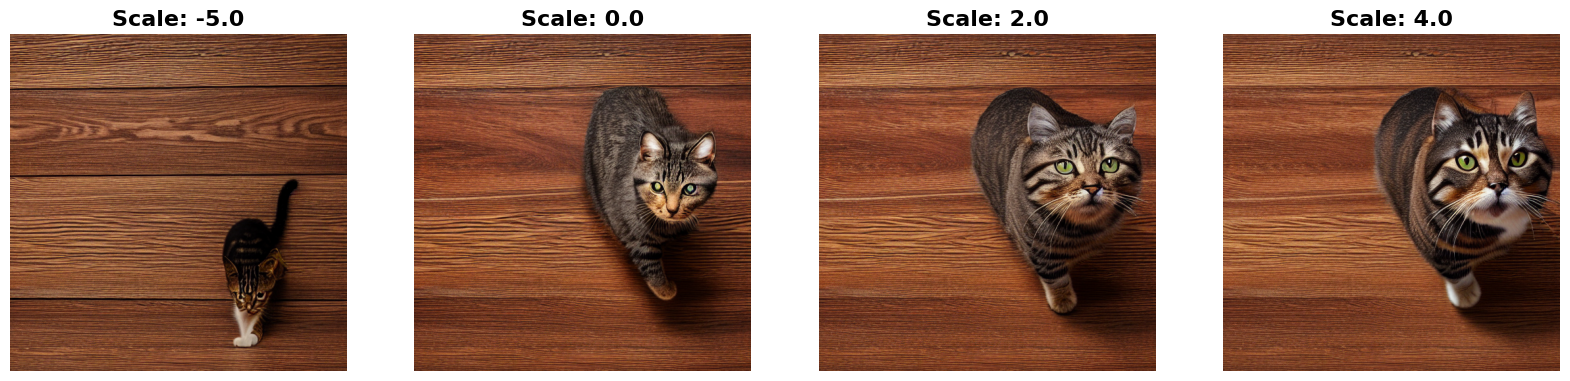

In [8]:
prompts = [
    "a highly detailed photorealistic full body shot of a cat standing on a wooden floor, 8k resolution",
]

# 我们设置一个梯度对比
scales = [-5.0, 0.0, 2.0, 4.0]

start_noise = 800
num_images_per_prompt = 1
negative_prompt = "split screen, missing limbs, bad anatomy, worst quality"
batch_size = 1
height = 512
width = 512
ddim_steps = 50
guidance_scale = 7.5
torch_device = device

for prompt in prompts:
    for _ in range(num_images_per_prompt):
        seed = 888  # 固定种子，确保每次生成的底图是同一个人，方便对比
        for lora_weight in lora_weights:

            if 'full' in lora_weight:
                train_method = 'full'
            else:
                train_method = 'noxattn'

            network_type = "c3lier"
            if train_method == 'xattn':
                network_type = 'lierla'

            modules = DEFAULT_TARGET_REPLACE
            if network_type == "c3lier":
                modules += UNET_TARGET_REPLACE_MODULE_CONV

            # 加载 UNet
            unet = UNet2DConditionModel.from_pretrained(
                pretrained_model_name_or_path, subfolder="unet", revision=revision
            )
            unet.requires_grad_(False)
            unet.to(device, dtype=weight_dtype)

            rank = 8 if 'rank8' in lora_weight else 4
            alpha = 1.0

            # 建立 LoRA 网络
            network = LoRANetwork(
                    unet, rank=rank, multiplier=1.0, alpha=alpha, train_method=train_method
                ).to(device, dtype=weight_dtype)

            # ================= 2. 修复文件读取报错问题 =================
            if lora_weight.endswith('.safetensors'):
                from safetensors.torch import load_file
                network.load_state_dict(load_file(lora_weight))
            else:
                # 兼容 .pt 格式
                network.load_state_dict(torch.load(lora_weight, map_location=device))
            # ==============================================================

            images_list = []
            print(f"正在测试 Prompt: {prompt} | 种子: {seed}")

            for scale in scales:
                print(f"正在生成 Scale = {scale} 的图像...")
                generator = torch.manual_seed(seed)
                text_input = tokenizer(prompt, padding="max_length", max_length=tokenizer.model_max_length, truncation=True, return_tensors="pt")
                text_embeddings = text_encoder(text_input.input_ids.to(torch_device))[0]

                max_length = text_input.input_ids.shape[-1]
                uncond_input = tokenizer([negative_prompt] * batch_size, padding="max_length", max_length=max_length, return_tensors="pt")
                uncond_embeddings = text_encoder(uncond_input.input_ids.to(torch_device))[0]

                text_embeddings = torch.cat([uncond_embeddings, text_embeddings])

                latents = torch.randn((batch_size, unet.in_channels, height // 8, width // 8), generator=generator)
                latents = latents.to(torch_device)

                noise_scheduler.set_timesteps(ddim_steps)
                latents = latents * noise_scheduler.init_noise_sigma
                latents = latents.to(weight_dtype)

                for t in noise_scheduler.timesteps:
                    if t > start_noise:
                        network.set_lora_slider(scale=0)
                    else:
                        network.set_lora_slider(scale=scale)

                    latent_model_input = torch.cat([latents] * 2)
                    latent_model_input = noise_scheduler.scale_model_input(latent_model_input, timestep=t)

                    with network:
                        with torch.no_grad():
                            noise_pred = unet(latent_model_input, t, encoder_hidden_states=text_embeddings).sample

                    noise_pred_uncond, noise_pred_text = noise_pred.chunk(2)
                    noise_pred = noise_pred_uncond + guidance_scale * (noise_pred_text - noise_pred_uncond)
                    latents = noise_scheduler.step(noise_pred, t, latents).prev_sample

                latents = 1 / 0.18215 * latents
                with torch.no_grad():
                    image = vae.decode(latents).sample
                image = (image / 2 + 0.5).clamp(0, 1)
                image = image.detach().cpu().permute(0, 2, 3, 1).numpy()
                images = (image * 255).round().astype("uint8")

                pil_images = [Image.fromarray(image) for image in images]
                images_list.append(pil_images[0])

            # 释放显存，防止显存爆炸
            del network, unet
            unet = None
            network = None
            torch.cuda.empty_cache()

            # 画图并排对比
            fig, ax = plt.subplots(1, len(images_list), figsize=(20, 5))
            for i, a in enumerate(ax):
                a.imshow(images_list[i])
                a.set_title(f"Scale: {scales[i]}", fontsize=16, fontweight='bold')
                a.axis('off')
            plt.show()

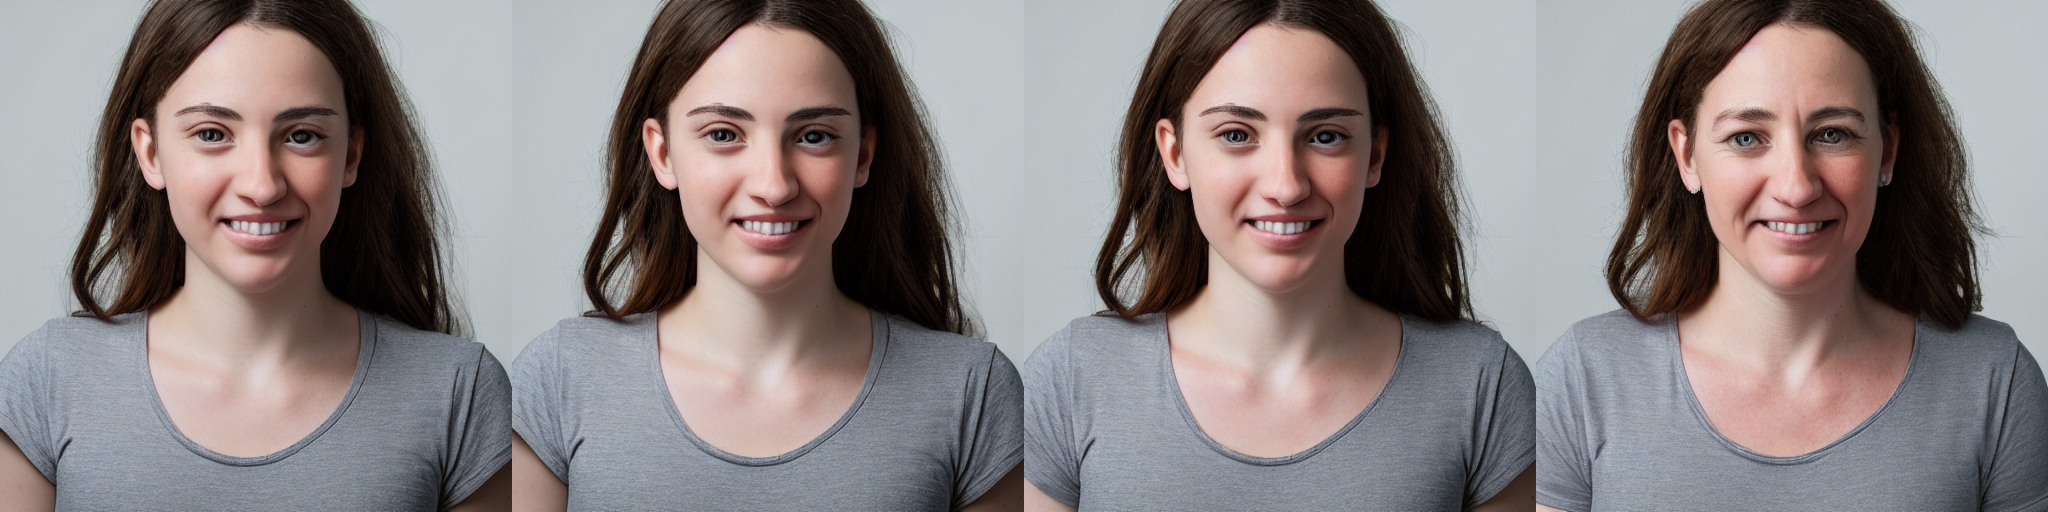

In [6]:
from PIL import Image
from IPython.display import display

# 获取单张图片的宽和高
w, h = images_list[0].size

# 创建一张足够宽的黑色大画布（宽度 = 4张图加起来，高度不变）
result_image = Image.new('RGB', (w * len(images_list), h))

# 把内存里的 4 张图，像贴邮票一样依次贴到大画布上
for i, img in enumerate(images_list):
    result_image.paste(img, (i * w, 0))

# 绕过 matplotlib，直接在 Jupyter 里强势展示！
display(result_image)

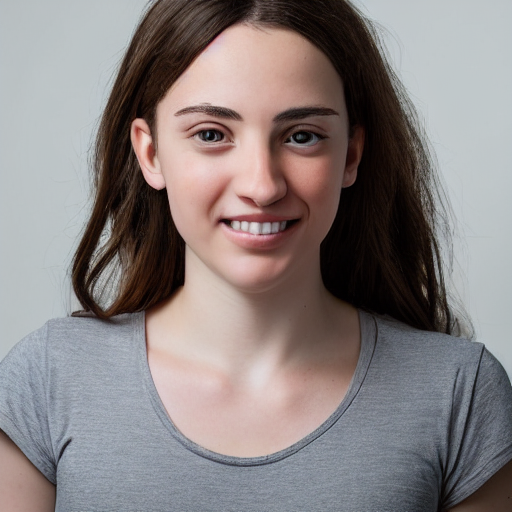

In [7]:

images_list[1]